# BƯỚC 4: HỆ THỐNG GỢI Ý VIỆC LÀM DỰA TRÊN NỘI DUNG (CONTENT-BASED FILTERING ENGINE)
## DỰ ÁN: IT JOB MARKET INTELLIGENCE
---
Notebook này tập trung xây dựng, chẩn đoán và đánh giá động cơ gợi ý việc làm CBF (Content-Based Filtering):
1. Nạp tập dữ liệu sạch & **lọc tin thuộc ngành IT** (Cleaned Dataset Ingestion)
2. Khảo sát sơ bộ & Kiểm tra cấu trúc dữ liệu (Data Schema Profiling)
3. Chuẩn hóa kỹ năng & Xây dựng "Content Soup" (Feature Engineering)
4. Vector hóa văn bản (TF-IDF với **tokenizer giữ nguyên C++/C#/.NET và tiếng Việt có dấu**) & Phân tích tương đồng giữa các Job
5. Thiết kế hệ thống chấm điểm đa thành phần (Composite Scoring Engine)
6. Thử nghiệm thực tế với các kịch bản đa dạng (Case Studies & Rationale)
7. Chẩn đoán phân bố điểm số Recommender (Score Distribution Diagnostic)
8. Đánh giá hiệu năng (Precision@K, NDCG@K, Diversity...) và **bảng ablation** so sánh trước/sau cải tiến

> **Yêu cầu:** chạy lại notebook `02_data_pipeline/02_data_cleaning_and_deduplication.ipynb` trước để có file `jobs_clean.csv` với các cột `job_tags` và `is_it`.

## 1. Nạp Tập Dữ Liệu Sạch (Cleaned Dataset Ingestion)

Nạp tập dữ liệu đã qua chu trình tiền xử lý (`jobs_clean.csv`). Dữ liệu cào về chứa cả những tin **không thuộc ngành IT** (thiết kế đồ họa, kinh doanh, kế toán...). Notebook 02 đã gắn cờ `is_it`; ở đây ta chỉ giữ lại các tin IT để chúng không chen vào danh sách gợi ý và không làm lệch trọng số IDF.

In [ ]:
import os
import re
import pandas as pd
import numpy as np

# 1. Tự động xác định đường dẫn gốc dự án
current_dir = os.path.dirname(os.path.abspath('__file__')) if '__file__' in locals() else os.getcwd()
project_root = current_dir
while not os.path.exists(os.path.join(project_root, 'data')) and os.path.dirname(project_root) != project_root:
    project_root = os.path.dirname(project_root)

csv_path = os.path.join(project_root, 'data', 'notebook', 'content_base', 'jobs_clean.csv')
if not os.path.exists(csv_path):
    csv_path = os.path.join(project_root, 'data', 'cleaned', 'jobs_clean.csv')

# 2. Đọc file CSV dữ liệu sạch mới nhất
jobs_all = pd.read_csv(csv_path)
for col in ['required_skills', 'job_tags', 'description_clean']:
    jobs_all[col] = jobs_all[col].fillna('')
assert {'is_it', 'job_tags'} <= set(jobs_all.columns), "Thiếu cột is_it/job_tags: hãy chạy lại notebook 02 trước."
print(f" Đã nạp dữ liệu sạch: {jobs_all.shape[0]:,} dòng x {jobs_all.shape[1]} cột  ({csv_path})")

# 3. Chỉ giữ tin thuộc ngành IT. Giữ lại jobs_all để so sánh ở phần đánh giá (ablation)
jobs = jobs_all[jobs_all['is_it']].reset_index(drop=True)
print(f" Sau khi lọc ngành IT: {len(jobs):,} tin ({len(jobs) / len(jobs_all):.1%}) | loại {len(jobs_all) - len(jobs):,} tin ngoài ngành")
jobs.head(3)

## 2. Khảo Sát & Kiểm Tra Chất Lượng Dữ Liệu (Data Quality & Schema Profiling)

Kiểm tra kiểu dữ liệu, các trường khuyết thiếu (Missing Rate) và rà soát các trường định lượng quan trọng phục vụ hệ thống gợi ý.


In [2]:
print("=== TỔNG QUAN KIỂU DỮ LIỆU & BỘ NHỚ ===")
jobs.info()

total_rows = len(jobs)
missing_stats = []

for col in jobs.columns:
    null_count = jobs[col].isnull().sum()
    empty_str_count = (jobs[col].astype(str).str.strip() == '').sum() if jobs[col].dtype == 'object' else 0
    total_missing = null_count + empty_str_count
    missing_pct = (total_missing / total_rows) * 100
    missing_stats.append({
        'Cột': col,
        'Số dòng thiếu': total_missing,
        'Tỷ lệ thiếu (%)': round(missing_pct, 2),
        'Độ đầy đủ (%)': round(100 - missing_pct, 2)
    })

missing_df = pd.DataFrame(missing_stats).sort_values(by='Tỷ lệ thiếu (%)', ascending=True).reset_index(drop=True)
print("=== BẢNG THỐNG KÊ ĐỘ HOÀN THIỆN CỦA DỮ LIỆU ===")
display(missing_df)


=== TỔNG QUAN KIỂU DỮ LIỆU & BỘ NHỚ ===
<class 'pandas.DataFrame'>
RangeIndex: 5182 entries, 0 to 5181
Data columns (total 18 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   job_id             5182 non-null   str    
 1   company_name       5182 non-null   str    
 2   title              5182 non-null   str    
 3   description_clean  5182 non-null   str    
 4   required_skills    5158 non-null   str    
 5   preferred_skills   27 non-null     str    
 6   experience_min     5182 non-null   float64
 7   experience_max     5181 non-null   float64
 8   location           5181 non-null   str    
 9   city               5182 non-null   str    
 10  salary_min         2127 non-null   float64
 11  salary_max         2395 non-null   float64
 12  employment_type    5182 non-null   str    
 13  work_mode          5182 non-null   str    
 14  deadline           5182 non-null   str    
 15  is_active          5182 non-null   bool   


,Cột,Số dòng thiếu,Tỷ lệ thiếu (%),Độ đầy đủ (%)
0,job_id,0,0.00,100.00
1,company_name,0,0.00,100.00
2,title,0,0.00,100.00
3,description_clean,0,0.00,100.00
4,experience_min,0,0.00,100.00
5,work_mode,0,0.00,100.00
6,deadline,0,0.00,100.00
7,city,0,0.00,100.00
8,is_active,0,0.00,100.00
9,employment_type,0,0.00,100.00


## 3. Chuẩn Hóa Kỹ Năng & Xây Dựng "Content Soup" (Feature Engineering)

### 1. Kỹ năng công nghệ vs. thẻ ngành
Ở notebook 02, cột thô của sàn đã được tách thành:
- `required_skills`: **chỉ kỹ năng công nghệ** (`Python`, `SQL`, `Docker`...), dùng cho điểm khớp kỹ năng;
- `job_tags`: thẻ ngành/lĩnh vực/chức danh (`IT - Phần mềm`, `Ngân hàng`, `QA Engineer`...), chỉ dùng làm ngữ cảnh văn bản.

Từ điển kỹ năng dưới đây dùng để **bóc kỹ năng từ đoạn CV** do người dùng nhập, và chuẩn hóa kỹ năng người dùng chọn (`ReactJS` ➔ `React`).

### 2. Xây dựng "Content Soup" có gán trọng số
$$\text{Content Soup} = (\text{Title} \times 3) + (\text{Required Skills} \times 4) + (\text{Job Tags} \times 1) + (\text{Description} \times 1)$$

In [ ]:
import re

# 1. TỪ ĐIỂN KỸ NĂNG CÔNG NGHỆ: tên viết tắt / biến thể ➔ tên chuẩn (python3 ➔ Python, k8s ➔ Kubernetes...)
CANONICAL_SKILL_MAP = {
    'python': 'Python', 'py': 'Python', 'python3': 'Python', 'java': 'Java', 'java core': 'Java',
    'javascript': 'JavaScript', 'js': 'JavaScript', 'typescript': 'TypeScript', 'ts': 'TypeScript',
    'c++': 'C++', 'cpp': 'C++', 'c#': 'C#', 'csharp': 'C#', 'php': 'PHP', 'golang': 'Golang', 'go': 'Golang',
    'ruby': 'Ruby', 'rust': 'Rust', 'scala': 'Scala', 'kotlin': 'Kotlin', 'swift': 'Swift', 'dart': 'Dart',
    'r': 'R', 'bash': 'Bash', 'shell': 'Shell', 'powershell': 'PowerShell', 'sql': 'SQL', 't-sql': 'T-SQL',
    'pl/sql': 'PL/SQL', 'power bi': 'Power BI', 'powerbi': 'Power BI', 'pbi': 'Power BI',
    'tableau': 'Tableau', 'excel': 'Excel', 'vba': 'VBA', 'macro': 'VBA', 'dax': 'DAX',
    'power query': 'Power Query', 'powerquery': 'Power Query', 'looker': 'Looker', 'looker studio': 'Looker',
    'metabase': 'Metabase', 'google data studio': 'Looker', 'qlik': 'Qlik', 'qliksense': 'Qlik',
    'qlikview': 'Qlik', 'ssis': 'SSIS', 'ssrs': 'SSRS', 'ssas': 'SSAS',
    'google analytics': 'Google Analytics', 'ga4': 'Google Analytics', 'a/b testing': 'A/B Testing',
    'ab testing': 'A/B Testing', 'etl': 'ETL', 'elt': 'ELT', 'data warehouse': 'Data Warehouse',
    'dwh': 'Data Warehouse', 'data lake': 'Data Lake', 'data modeling': 'Data Modeling',
    'data pipeline': 'Data Pipeline', 'bigquery': 'BigQuery', 'snowflake': 'Snowflake',
    'spark': 'Apache Spark', 'pyspark': 'PySpark', 'apache spark': 'Apache Spark', 'hadoop': 'Hadoop',
    'hive': 'Hive', 'airflow': 'Apache Airflow', 'apache airflow': 'Apache Airflow', 'dbt': 'dbt',
    'kafka': 'Apache Kafka', 'apache kafka': 'Apache Kafka', 'spark streaming': 'Apache Spark',
    'machine learning': 'Machine Learning', 'ml': 'Machine Learning', 'deep learning': 'Deep Learning',
    'dl': 'Deep Learning', 'nlp': 'NLP', 'natural language processing': 'NLP',
    'computer vision': 'Computer Vision', 'cv': 'Computer Vision', 'pandas': 'Pandas', 'numpy': 'NumPy',
    'scikit-learn': 'Scikit-Learn', 'sklearn': 'Scikit-Learn', 'tensorflow': 'TensorFlow',
    'pytorch': 'PyTorch', 'keras': 'Keras', 'generative ai': 'Generative AI', 'genai': 'Generative AI',
    'llm': 'LLM', 'statistics': 'Statistics', 'spring boot': 'Spring Boot', 'springboot': 'Spring Boot',
    'spring': 'Spring Boot', 'django': 'Django', 'fastapi': 'FastAPI', 'flask': 'Flask',
    'node.js': 'Node.js', 'nodejs': 'Node.js', 'node': 'Node.js', 'express.js': 'Express.js',
    'expressjs': 'Express.js', 'express': 'Express.js', 'nestjs': 'NestJS', 'nest.js': 'NestJS',
    '.net': '.NET', 'dotnet': '.NET', '.net core': '.NET', 'asp.net': '.NET', 'laravel': 'Laravel',
    'ruby on rails': 'Ruby on Rails', 'rails': 'Ruby on Rails', 'gin': 'Gin', 'graphql': 'GraphQL',
    'rest api': 'REST API', 'restful': 'REST API', 'restful api': 'REST API', 'grpc': 'gRPC',
    'microservices': 'Microservices', 'microservice': 'Microservices', 'react': 'React', 'reactjs': 'React',
    'react.js': 'React', 'react native': 'React Native', 'reactnative': 'React Native', 'vue': 'Vue',
    'vuejs': 'Vue', 'vue.js': 'Vue', 'angular': 'Angular', 'angularjs': 'Angular', 'next.js': 'Next.js',
    'nextjs': 'Next.js', 'nuxt.js': 'Nuxt.js', 'nuxtjs': 'Nuxt.js', 'svelte': 'Svelte', 'flutter': 'Flutter',
    'android': 'Android', 'ios': 'iOS', 'html': 'HTML/CSS', 'html5': 'HTML/CSS', 'css': 'HTML/CSS',
    'css3': 'HTML/CSS', 'tailwind': 'TailwindCSS', 'tailwindcss': 'TailwindCSS', 'bootstrap': 'Bootstrap',
    'redux': 'Redux', 'postgresql': 'PostgreSQL', 'postgres': 'PostgreSQL', 'psql': 'PostgreSQL',
    'mysql': 'MySQL', 'sql server': 'SQL Server', 'mssql': 'SQL Server', 'oracle': 'Oracle Database',
    'mongodb': 'MongoDB', 'mongo': 'MongoDB', 'redis': 'Redis', 'elasticsearch': 'Elasticsearch',
    'elastic': 'Elasticsearch', 'cassandra': 'Cassandra', 'dynamodb': 'DynamoDB', 'sqlite': 'SQLite',
    'mariadb': 'MariaDB', 'firebase': 'Firebase', 'neo4j': 'Neo4j', 'aws': 'AWS',
    'amazon web services': 'AWS', 'azure': 'Azure', 'microsoft azure': 'Azure', 'gcp': 'GCP',
    'google cloud': 'GCP', 'docker': 'Docker', 'kubernetes': 'Kubernetes', 'k8s': 'Kubernetes',
    'ci/cd': 'CI/CD', 'cicd': 'CI/CD', 'git': 'Git', 'github': 'Git', 'gitlab': 'Git', 'linux': 'Linux',
    'terraform': 'Terraform', 'ansible': 'Ansible', 'jenkins': 'Jenkins', 'nginx': 'Nginx',
    'prometheus': 'Prometheus', 'grafana': 'Grafana', 'rabbitmq': 'RabbitMQ',
    'manual testing': 'Manual Testing', 'manual test': 'Manual Testing',
    'automation testing': 'Automation Testing', 'automation test': 'Automation Testing',
    'selenium': 'Selenium', 'cypress': 'Cypress', 'playwright': 'Playwright', 'postman': 'Postman',
    'jmeter': 'JMeter', 'unit test': 'Unit Testing', 'unit testing': 'Unit Testing', 'appium': 'Appium',
    'jira': 'Jira', 'confluence': 'Confluence', 'figma': 'Figma', 'photoshop': 'Photoshop', 'agile': 'Agile',
    'scrum': 'Scrum', 'oop': 'OOP', 'system design': 'System Design', 'an ninh mạng': 'An Ninh Mạng',
    'cybersecurity': 'An Ninh Mạng',
}

# 2. Khái niệm công nghệ hay gặp trong thẻ của sàn nhưng chưa có trong từ điển trên
TECH_EXTRA = {
    'data analysis': 'Data Analysis', 'data analytics': 'Data Analysis', 'phân tích dữ liệu': 'Data Analysis',
    'data science': 'Data Science', 'big data': 'Big Data', 'business intelligence': 'Business Intelligence',
    'data management': 'Data Management', 'data governance': 'Data Governance',
    'cloud': 'Cloud', 'điện toán đám mây (cloud)': 'Cloud', 'devops': 'DevOps', 'api': 'API', 'api testing': 'API Testing',
    'erp': 'ERP', 'sap': 'SAP', 'scada': 'SCADA', 'vmware': 'VMware', 'hosting': 'Hosting', 'server': 'Server',
    'software testing': 'Software Testing', 'kiểm thử phần mềm': 'Software Testing', 'qa': 'QA',
    'information security': 'An Ninh Mạng', 'it security': 'An Ninh Mạng', 'an toàn thông tin': 'An Ninh Mạng',
    'network security': 'Network Security',
    'lập trình nhúng': 'Embedded', 'embedded': 'Embedded', 'network': 'Networking', 'quản trị mạng': 'Networking',
    'system administration': 'System Administration', 'quản trị hệ thống': 'System Administration',
    'agile scrum': 'Agile', 'ux design': 'UX Design', 'ui': 'UI Design',
    'ms sql': 'SQL Server', 'python programming': 'Python', 'java spring boot': 'Spring Boot',
    'ci': 'CI/CD', 'cd': 'CI/CD', 'cd methodologies': 'CI/CD', 'ai': 'AI', 'blockchain': 'Blockchain',
}
TECH_LOOKUP = {**CANONICAL_SKILL_MAP, **TECH_EXTRA}

# 3. Khóa quá mơ hồ khi quét VĂN BẢN TỰ DO (vd 'go' trong "go to market", 'cv' trong "gửi CV", 'ml' viết tắt)
#    ➔ chỉ chấp nhận chúng khi xuất hiện như một THẺ rõ ràng, không quét từ mô tả.
AMBIGUOUS_FREE_TEXT_KEYS = {'cv', 'go', 'r', 'ml', 'dl', 'py', 'ts', 'js', 'macro', 'gin', 'spring', 'express',
                            'node', 'shell', 'elastic', 'ai', 'ui', 'ci', 'cd', 'api', 'qa', 'server', 'cloud', 'network', 'sap'}

# 4. Mẫu nhận diện thẻ RÁC (phúc lợi, kinh nghiệm, học vấn, nhân thân...)
JUNK_PATTERN = re.compile(
    r'bảo hiểm|thưởng|bonus|du lịch|team\s*building|khám sức khỏe|phụ cấp|xăng|tai nghe|cước|điện thoại|phương tiện|'
    r'giờ hành chính|giọng|phát âm|diễn đạt|kinh nghiệm|trở lên|đại học|cao đẳng|trung cấp|tuổi|xem tất cả|'
    r'toàn thời gian|bán thời gian|thực tập|signing', re.IGNORECASE)

# 5. Regex quét kỹ năng trong văn bản. Dùng lookaround thay cho \b để nhận đúng C++, C#, .NET, CI/CD
TECH_PATTERNS = [
    (re.compile(r'(?<![\w+#.])' + re.escape(key) + r'(?![\w+#])'), canonical)
    for key, canonical in TECH_LOOKUP.items() if key not in AMBIGUOUS_FREE_TEXT_KEYS
]


def extract_skills_from_text(text):
    """Bóc tách kỹ năng công nghệ chuẩn hóa từ văn bản tự do (CV / đoạn mô tả)."""
    text_lower = str(text).lower()
    found, seen = [], set()
    for pattern, canonical in TECH_PATTERNS:
        if canonical.lower() not in seen and pattern.search(text_lower):
            seen.add(canonical.lower()); found.append(canonical)
    return found


def normalize_user_skills(skills):
    """Chuẩn hóa kỹ năng người dùng nhập tay: 'reactjs' ➔ 'React', 'k8s' ➔ 'Kubernetes'."""
    return [TECH_LOOKUP.get(str(s).strip().lower(), str(s).strip()) for s in (skills or []) if str(s).strip()]


# Xây dựng Content Soup gán trọng số
def build_content_soup(row):
    title = str(row.get('title', '')) if pd.notnull(row.get('title')) else ''
    skills = str(row.get('required_skills', '')) if pd.notnull(row.get('required_skills')) else ''
    tags = str(row.get('job_tags', '')) if pd.notnull(row.get('job_tags')) else ''
    desc = str(row.get('description_clean', '')) if pd.notnull(row.get('description_clean')) else ''
    return f"{title} {title} {title} {skills} {skills} {skills} {skills} {tags} {desc}".strip()

jobs['content_soup'] = jobs.apply(build_content_soup, axis=1)

print("=== KIỂM TRA BÓC TÁCH KỸ NĂNG TỪ ĐOẠN CV ===")
print(extract_skills_from_text("Có 2 năm làm C++, C#, .NET Core, CI/CD, Node.js. Gửi CV về HR. Go to market."))
print("\n=== MẪU CONTENT SOUP CỦA 2 CÔNG VIỆC ĐẦU TIÊN ===")
for idx, s in enumerate(jobs['content_soup'].head(2)):
    print(f"\n[Job {idx+1}] {jobs.iloc[idx]['title']}:")
    print(s[:250] + "...")

## 4. Vector Hóa Văn Bản (TF-IDF) & Phân Tích Tương Đồng Giữa Các Job

### Vì sao phải thay `token_pattern`?
Cấu hình cũ `token_pattern=r"(?u)\b[a-zA-Z0-9_+#\.]+\b"` **không hề giữ được** `C++`/`C#`, và **làm mất toàn bộ chữ tiếng Việt có dấu**:

| Văn bản | Tokenizer cũ | Tokenizer mới |
|---|---|---|
| `C++` , `C#` | `c`, `c` (hai ngôn ngữ bị gộp làm một) | `cpp`, `csharp` |
| `.NET`, `CI/CD` | `net`, `ci`, `cd` | `dotnet`, `cicd` |
| `kinh nghiệm lập trình` | *(mất sạch, vì ký tự có dấu không nằm trong `[a-zA-Z]`)* | `kinh`, `nghiệm`, `lập`, `trình` |

**Cách sửa:** (1) tiền xử lý thay `C++`➔`cpp`, `C#`➔`csharp`... bằng token ASCII trước khi tách từ; (2) dùng `\w\w+` (nhận chữ Unicode) làm `token_pattern`.

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
import time

# 1. Chuẩn hóa token IT đặc thù TRƯỚC khi tách từ (regex áp dụng trên chuỗi đã lower-case)
_TECH_REPLACEMENTS = [
    (re.compile(r"(?<![\w+])c\+\+(?![\w+])"), " cpp "),
    (re.compile(r"(?<![\w#])c#(?![\w#])"), " csharp "),
    (re.compile(r"(?<![\w])(?:asp)?\.net(?:\s*core)?(?![\w])"), " dotnet "),
    (re.compile(r"(?<![\w])node\.?js(?![\w])"), " nodejs "),
    (re.compile(r"(?<![\w])react\.?js(?![\w])"), " reactjs "),
    (re.compile(r"(?<![\w])vue\.?js(?![\w])"), " vuejs "),
    (re.compile(r"(?<![\w])next\.?js(?![\w])"), " nextjs "),
    (re.compile(r"(?<![\w])ci\s*/\s*cd(?![\w])"), " cicd "),
    (re.compile(r"(?<![\w])a\s*/\s*b\s+test"), " abtest"),
    (re.compile(r"(?<![\w])pl\s*/\s*sql(?![\w])"), " plsql "),
    (re.compile(r"(?<![\w])ui\s*/\s*ux(?![\w])|(?<![\w])ux\s*/\s*ui(?![\w])"), " uiux "),
    (re.compile(r"(?<![\w])front[\s-]?end(?![\w])"), " frontend "),
    (re.compile(r"(?<![\w])back[\s-]?end(?![\w])"), " backend "),
    (re.compile(r"(?<![\w])full[\s-]?stack(?![\w])"), " fullstack "),
]

def normalize_tech_text(text):
    s = str(text).lower()
    for pat, rep in _TECH_REPLACEMENTS:
        s = pat.sub(rep, s)
    return s

TOKEN_PATTERN = r"(?u)\b\w\w+\b"      # chữ/số Unicode (giữ tiếng Việt có dấu), tối thiểu 2 ký tự

# 2. So sánh trực quan tokenizer cũ và mới
sample = "C++ C# .NET CI/CD Node.js kinh nghiệm lập trình"
old_tokens = TfidfVectorizer(token_pattern=r"(?u)\b[a-zA-Z0-9_+#\.]+\b").build_analyzer()(sample)
new_tokens = TfidfVectorizer(preprocessor=normalize_tech_text, token_pattern=TOKEN_PATTERN).build_analyzer()(sample)
print(f"Văn bản   : {sample}")
print(f"Tokenizer cũ : {old_tokens}")
print(f"Tokenizer mới: {new_tokens}\n")

# 3. Huấn luyện TF-IDF trên Content Soup
start_time = time.time()
tfidf = TfidfVectorizer(
    preprocessor=normalize_tech_text,
    token_pattern=TOKEN_PATTERN,
    max_features=10000,
    ngram_range=(1, 2),
    min_df=2
)
tfidf_matrix = tfidf.fit_transform(jobs['content_soup'])

elapsed = time.time() - start_time
print(f" Đã vector hóa thành công: {tfidf_matrix.shape[0]:,} jobs x {tfidf_matrix.shape[1]:,} features")
print(f" Thời gian thực thi TF-IDF: {elapsed:.2f} giây")

### Heatmap Cosine Similarity giữa các bài đăng mẫu (Job-to-Job)


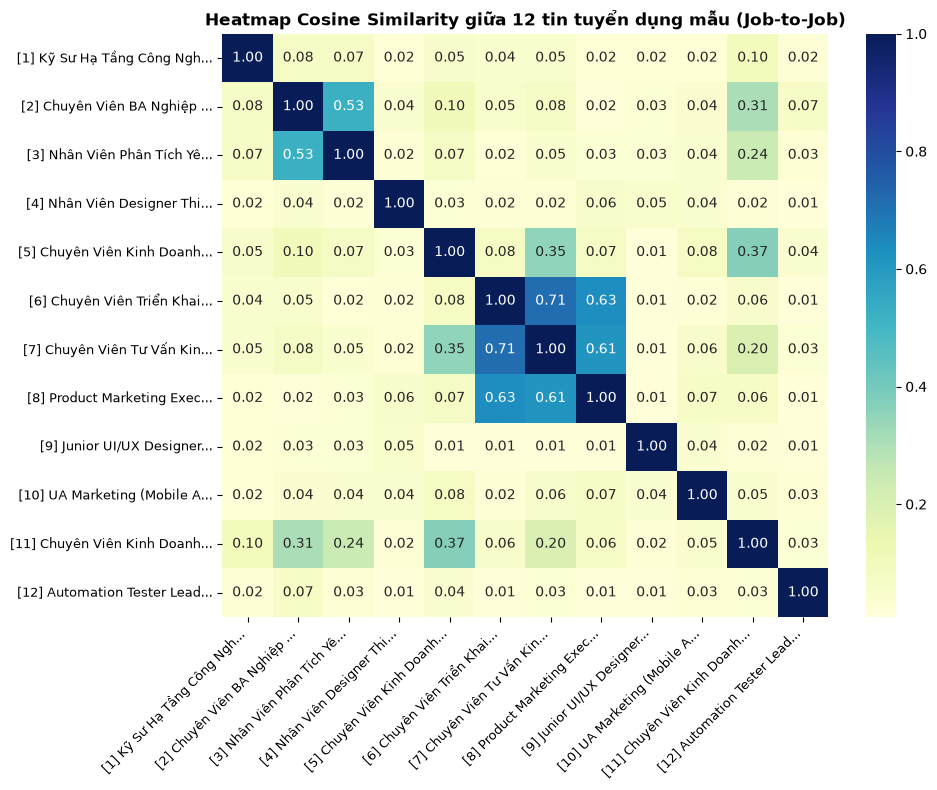

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns
sample_submatrix = cosine_similarity(tfidf_matrix[:12], tfidf_matrix[:12])
job_short_titles = [f"[{i+1}] {t[:22]}..." for i, t in enumerate(jobs['title'].head(12))]

plt.figure(figsize=(10, 8))
sns.heatmap(sample_submatrix, annot=True, fmt=".2f", cmap='YlGnBu',
            xticklabels=job_short_titles, yticklabels=job_short_titles, cbar=True)
plt.title("Heatmap Cosine Similarity giữa 12 tin tuyển dụng mẫu (Job-to-Job)", fontsize=12, fontweight='bold')
plt.xticks(rotation=45, ha='right', fontsize=9)
plt.yticks(fontsize=9)
plt.tight_layout()
plt.show()


## 5. Thiết Kế Hệ Thống Chấm Điểm Đa Thành Phần (Composite Scoring Engine)

### Công thức điểm tổng hợp:
$$\text{Score}(j, u) = 0.30 S_{skills} + 0.40 S_{text} + 0.10 S_{experience} + 0.10 S_{location/work\ mode} + 0.10 S_{salary}$$

### Ba lỗi của phiên bản đầu đã được sửa (phát hiện khi chạy toàn pipeline: Precision@5 chỉ ~0,48 trong khi chỉ dùng văn bản đạt ~0,87)

| # | Lỗi | Hậu quả | Cách sửa |
|---|---|---|---|
| 1 | $S_{skills}$ = *tỷ lệ kỹ năng job yêu cầu mà bạn có*. Job chỉ yêu cầu 1 kỹ năng (bạn có nó) đạt ngay **100%** | Job lệch nghề nhưng ít yêu cầu vẫn thắng job đúng nghề | Nhân thêm **hệ số tin cậy** $\frac{m}{m+1}$ ($m$ = số kỹ năng khớp): khớp 1 kỹ năng chỉ được ×0,5, khớp 5 kỹ năng được ×0,83 |
| 2 | Cosine TF-IDF hiếm khi vượt 0,5 nhưng các thành phần khác trải rộng 0-1 | Trọng số 30% của văn bản thực tế chỉ còn ~10-15 điểm, **bị các thành phần khác lấn át** | **Chuẩn hóa theo truy vấn**: $S_{text} = \frac{\cos(u, j)}{\max_j \cos(u, j)}$, job giống nhất luôn đạt 1,0 |
| 3 | Job **không liệt kê kỹ năng nào** (21% kho) bị gán $S_{skills} = 0{,}5$ giả | Điểm bịa đặt, không dựa trên bằng chứng nào | Coi là *không có dữ liệu*: bỏ thành phần này |

- **Dynamic Re-weighting:** thành phần nào thiếu dữ liệu (lương *"Thỏa thuận"*, job không có kỹ năng) bị loại và các trọng số còn lại được chuẩn hóa về tổng $1{,}0$: $w'_i = \frac{w_i}{\sum_{k \in \text{có dữ liệu}} w_k}$.
- **Trọng số kỹ năng : văn bản = 0,30 : 0,40** (trước đây 0,40 : 0,30) được chọn dựa trên bảng quét ở mục **8.3**.
- Các hàm tính điểm ngắn được nhóm lại; các hàm dài (`recommend_jobs`, `analyze_cv_fit_for_job`) tách thành từng cell.

### 5.1. Các hàm tính điểm thành phần chuẩn hóa [0, 1] & Cơ chế co giãn trọng số


In [ ]:
def compute_skill_score(user_skills, job_required_skills, job_preferred_skills=None, mode='v2'):
    """
    S_skills: mức khớp kỹ năng bắt buộc [0, 1]; trả về None nếu job không liệt kê kỹ năng nào (mode v2).
      - 'v1' (cũ)  : coverage = số kỹ năng khớp / số kỹ năng job yêu cầu  (job yêu cầu 1 kỹ năng bạn có => 100%)
      - 'v2' (mới) : coverage x m/(m+1) với m = số kỹ năng khớp  (khớp càng nhiều, bằng chứng càng đáng tin)
    (Trường preferred_skills đã được loại bỏ do dữ liệu thực tế bị rỗng >99%).
    """
    user_set = set(s.lower() for s in user_skills if s and s.lower() != 'nan')
    req_set = set(s.lower() for s in job_required_skills if s and s.lower() != 'nan') if job_required_skills else set()

    if not req_set:
        return None if mode == 'v2' else 0.5
    matched = len(user_set & req_set)
    coverage = matched / len(req_set)
    if mode == 'v1':
        return round(coverage, 3)
    return round(coverage * matched / (matched + 1), 3)

def compute_exp_score(user_exp, job_min_exp, job_max_exp=None):
    """S_experience: Điểm phù hợp số năm kinh nghiệm."""
    if pd.isna(job_min_exp) or job_min_exp == 0:
        return 1.0
    diff = user_exp - job_min_exp
    if diff >= 0:
        if pd.notna(job_max_exp) and user_exp > job_max_exp + 3:
            return 0.85 # Hơi overqualified
        return 1.0
    elif diff >= -1.0:
        return 0.7 # Thiếu dưới 1 năm
    elif diff >= -2.0:
        return 0.4 # Thiếu 1-2 năm
    else:
        return 0.1 # Thiếu quá nhiều

def compute_location_mode_score(user_city, user_modes, job_city, job_mode):
    """S_location/mode: Điểm kết hợp địa điểm và mô hình làm việc."""
    score_mode = 0.5
    score_city = 0.5
    job_mode_str = str(job_mode).lower()
    
    if isinstance(user_modes, str):
        user_modes = [user_modes]
    user_modes_lower = [m.lower() for m in user_modes] if user_modes else ['tất cả']
    
    if 'tất cả' in user_modes_lower or not user_modes:
        score_mode = 1.0
    elif any(m in job_mode_str for m in user_modes_lower):
        score_mode = 1.0
    elif 'remote' in job_mode_str:
        score_mode = 0.9 # Job Remote phù hợp gần như mọi ứng viên
    elif 'hybrid' in job_mode_str and any('remote' in m for m in user_modes_lower):
        score_mode = 0.8
    else:
        score_mode = 0.2
        
    if user_city == 'Tất cả' or not user_city:
        score_city = 1.0
    elif str(job_city).lower() == str(user_city).lower():
        score_city = 1.0
    elif 'remote' in job_mode_str:
        score_city = 1.0 # Tin Remote không rào cản địa lý
    else:
        score_city = 0.1
        
    return round(0.5 * score_city + 0.5 * score_mode, 3)

def compute_salary_score(user_min_salary, job_salary_min, job_salary_max):
    """S_salary: Trả về None nếu bài đăng không có số liệu lương cụ thể."""
    if pd.isna(job_salary_max) and pd.isna(job_salary_min):
        return None
    max_sal = job_salary_max if pd.notna(job_salary_max) else job_salary_min
    if not user_min_salary or user_min_salary == 0:
        return 1.0
    if max_sal >= user_min_salary:
        return 1.0
    else:
        ratio = max_sal / user_min_salary
        return round(max(0.0, float(ratio)), 3)

def compute_composite_score(s_skills, s_text, s_exp, s_loc, s_sal, base_weights=None):
    """
    Tính điểm tổng hợp Score(j, u). Thành phần nào là None (thiếu dữ liệu: lương thỏa thuận, job không có kỹ năng)
    bị loại và các trọng số còn lại được co giãn về tổng 1.0.
    Score = 0.30*S_skills + 0.40*S_text + 0.10*S_exp + 0.10*S_loc + 0.10*S_sal
    """
    if base_weights is None:
        base_weights = {'skills': 0.30, 'text': 0.40, 'exp': 0.10, 'loc': 0.10, 'sal': 0.10}
    scores = {'skills': s_skills, 'text': s_text, 'exp': s_exp, 'loc': s_loc, 'sal': s_sal}
    available = {k: w for k, w in base_weights.items() if scores[k] is not None}
    total_w = sum(available.values())
    weights = {k: w / total_w for k, w in available.items()}
    total_score = sum(weights[k] * scores[k] for k in weights)
    return round(total_score, 4), weights

### 5.2. Các hàm hỗ trợ hiển thị & Sinh lời giải thích (Rationale Generator)


In [7]:
def generate_rationale(matched_skills, missing_skills, user_exp, job_min_exp, job_mode, is_salary_fit):
    """Sinh câu giải thích gợi ý trực quan."""
    reasons = []
    total_skills = len(matched_skills) + len(missing_skills)
    if total_skills > 0:
        matched_str = ', '.join(matched_skills[:3]) if matched_skills else 'Chưa trùng trực tiếp'
        reasons.append(f"Khớp {len(matched_skills)}/{total_skills} kỹ năng ({matched_str})")
    if pd.isna(job_min_exp) or job_min_exp == 0:
        reasons.append("Không đòi hỏi số năm kinh nghiệm")
    elif user_exp >= job_min_exp:
        reasons.append(f"Kinh nghiệm phù hợp ({user_exp:.0f} năm >= yêu cầu {job_min_exp:.0f} năm)")
    else:
        reasons.append(f"Yêu cầu {job_min_exp:.0f} năm (bạn có {user_exp:.0f} năm)")
    reasons.append(f"Hình thức {job_mode}")
    if is_salary_fit is True:
        reasons.append("Đạt kỳ vọng lương")
    elif is_salary_fit is None:
        reasons.append("Lương thỏa thuận")
    else:
        reasons.append("Thấp hơn kỳ vọng lương")
    return "; ".join(reasons)

def format_salary_display(s_min, s_max):
    """Định dạng hiển thị mức lương trực quan."""
    if pd.notnull(s_min) and pd.notnull(s_max):
        if s_min == s_max:
            return f"{s_min/1e6:.0f} tr"
        return f"{s_min/1e6:.0f} - {s_max/1e6:.0f} tr"
    elif pd.notnull(s_max):
        return f"Lên đến {s_max/1e6:.0f} tr"
    elif pd.notnull(s_min):
        return f"Từ {s_min/1e6:.0f} tr"
    return "Thoả thuận"

print(" Đã khởi tạo các hàm sinh lời giải thích (Rationale) và định dạng lương!")


 Đã khởi tạo các hàm sinh lời giải thích (Rationale) và định dạng lương!


### 5.3. Bộ chấm điểm dùng chung (`score_components` ➔ `combine_scores`) và hàm gợi ý `recommend_jobs`

Để **hàm gợi ý và báo cáo 1:1 luôn cho cùng một con số**, toàn bộ phép tính được tách thành 3 bước dùng chung:

1. `score_components(...)`: tính 5 điểm thành phần cho **mọi** job (mảng, `NaN` = thiếu dữ liệu);
2. `combine_scores(...)`: gộp bằng trọng số, tự co giãn lại khi có thành phần `NaN`;
3. `recommend_jobs(...)` / `analyze_cv_fit_for_job(...)`: chỉ việc sắp xếp / trình bày kết quả.

In [ ]:
DEFAULT_WEIGHTS = {'skills': 0.30, 'text': 0.40, 'exp': 0.10, 'loc': 0.10, 'sal': 0.10}
COMPONENTS = ['skills', 'text', 'exp', 'loc', 'sal']


def score_components(target_title="", cv_text="", skills=None, user_exp=1.0, preferred_city="Tất cả",
                     preferred_work_modes=None, min_salary=None, skill_mode='v2', normalize_text=True):
    """
    Bước 1: tính 5 điểm thành phần cho TẤT CẢ job.
    Trả về dict gồm: user_skills, raw_sim (cosine thô), comps (DataFrame 5 cột, NaN = thiếu dữ liệu), active (mask tin còn hạn).
    skill_mode='v1' và normalize_text=False tái hiện công thức CŨ (dùng cho bảng ablation).
    """
    all_user_skills = list(dict.fromkeys(normalize_user_skills(skills) + (extract_skills_from_text(cv_text) if cv_text else [])))

    parts = []
    if target_title:
        parts.extend([target_title] * 3)
    if all_user_skills:
        parts.extend([" ".join(all_user_skills)] * 4)
    if cv_text:
        parts.append(cv_text)
    profile_soup = " ".join(parts).strip()
    if not profile_soup:
        return None

    raw_sim = cosine_similarity(tfidf.transform([profile_soup]), tfidf_matrix).flatten()
    # Chuẩn hóa theo truy vấn: job giống nhất đạt 1.0 (cosine thô hiếm khi vượt 0.5 nên sẽ bị các thành phần khác lấn át)
    text_scores = raw_sim / raw_sim.max() if (normalize_text and raw_sim.max() > 0) else raw_sim

    # Tách sẵn danh sách kỹ năng của từng job một lần (tăng tốc khi gọi nhiều lần)
    if 'req_list' not in jobs.columns:
        jobs['req_list'] = jobs['required_skills'].map(
            lambda x: [s.strip() for s in str(x).split(',') if s.strip() and s.strip().lower() != 'nan'])

    rows = []
    for idx, row in enumerate(jobs.itertuples(index=False)):
        s_skill = compute_skill_score(all_user_skills, row.req_list, mode=skill_mode)
        s_exp = compute_exp_score(user_exp, row.experience_min, row.experience_max)
        s_loc = compute_location_mode_score(preferred_city, preferred_work_modes, row.city, row.work_mode)
        s_sal = compute_salary_score(min_salary, row.salary_min, row.salary_max)
        rows.append((np.nan if s_skill is None else s_skill, float(text_scores[idx]), s_exp, s_loc,
                     np.nan if s_sal is None else s_sal))
    comps = pd.DataFrame(rows, columns=COMPONENTS)
    return {'user_skills': all_user_skills, 'raw_sim': raw_sim, 'comps': comps, 'active': jobs['is_active'].values.astype(bool)}


def combine_scores(comps, weights=None):
    """
    Bước 2: gộp 5 điểm thành phần thành tổng điểm [0, 1] cho mọi job.
    Thành phần NaN bị loại và trọng số còn lại được co giãn về tổng 1.0 (cùng quy tắc với compute_composite_score).
    """
    w = np.array([(weights or DEFAULT_WEIGHTS)[k] for k in COMPONENTS], dtype=float)
    M = comps[COMPONENTS].values
    available_weight = (~np.isnan(M) * w).sum(axis=1)
    return np.nansum(M * w, axis=1) / available_weight


def recommend_jobs(
    target_title="", cv_text="", skills=None, user_exp=1.0, preferred_city="Tất cả",
    preferred_work_modes=None, min_salary=None, top_n=10, weights=None, skill_mode='v2', normalize_text=True
):
    """Gợi ý việc làm: Vị trí + Kỹ năng + Văn bản CV + Kinh nghiệm + Địa điểm/Hình thức + Lương mong muốn."""
    sc = score_components(target_title, cv_text, skills, user_exp, preferred_city, preferred_work_modes,
                          min_salary, skill_mode, normalize_text)
    if sc is None:
        print(" Vui lòng cung cấp ít nhất một thông tin: Vị trí (target_title), Kỹ năng (skills), hoặc Văn bản CV (cv_text).")
        return pd.DataFrame()

    total = combine_scores(sc['comps'], weights)
    total = np.where(sc['active'], total, -1.0)                 # bỏ tin hết hạn
    top_idx = np.argsort(-total, kind='stable')[:top_n]

    user_skills_lower = {s.lower() for s in sc['user_skills']}
    out = []
    for idx in top_idx:                                          # chỉ sinh lời giải thích cho top_n
        row, c = jobs.iloc[idx], sc['comps'].iloc[idx]
        req = row['req_list']
        matched = [s for s in req if s.lower() in user_skills_lower]
        missing = [s for s in req if s.lower() not in user_skills_lower]
        sal_fit = None if np.isnan(c['sal']) else bool(c['sal'] == 1.0)
        out.append({
            'job_id': row['job_id'], 'Tiêu đề': row['title'], 'Công ty': row['company_name'],
            'Tổng điểm (%)': round(total[idx] * 100, 1),
            'Điểm kỹ năng (%)': None if np.isnan(c['skills']) else round(c['skills'] * 100, 1),
            'Điểm văn bản (%)': round(c['text'] * 100, 1),
            'Cosine gốc (%)': round(float(sc['raw_sim'][idx]) * 100, 1),
            'Điểm kinh nghiệm (%)': round(c['exp'] * 100, 1),
            'Điểm vị trí/hình thức (%)': round(c['loc'] * 100, 1),
            'Lời giải thích': generate_rationale(matched, missing, user_exp, row['experience_min'], row['work_mode'], sal_fit),
            'Kinh nghiệm yêu cầu': f"{row['experience_min']} năm" if pd.notnull(row['experience_min']) else 'Không yêu cầu',
            'Hình thức': row['work_mode'], 'Thành phố': row['city'],
            'Mức lương': format_salary_display(row['salary_min'], row['salary_max']),
            'job_url': row['job_url'], 'company_logo_url': row['company_logo_url']})
    return pd.DataFrame(out)

print(" Đã khởi tạo score_components / combine_scores / recommend_jobs hoàn chỉnh!")

### 5.4. Hàm Báo Cáo Đánh Giá Độ Phù Hợp 1:1 (`analyze_cv_fit_for_job`)


In [ ]:
def analyze_cv_fit_for_job(job_identifier, cv_text="", skills=None, user_exp=1.0, target_title="",
                           preferred_city="Tất cả", preferred_work_modes=None, min_salary=None, weights=None):
    """
    Báo cáo chi tiết độ phù hợp 1:1 giữa hồ sơ và MỘT job. Dùng chung score_components/combine_scores với
    recommend_jobs nên Tổng điểm và thứ hạng luôn khớp với bảng gợi ý khi truyền cùng tham số hồ sơ.
    job_identifier: job_id (khuyên dùng), chỉ số dòng, hoặc một đoạn của tiêu đề.
    """
    if isinstance(job_identifier, (int, np.integer)):
        idx = int(job_identifier)
    else:
        match = jobs[jobs['job_id'] == job_identifier]
        if match.empty:
            match = jobs[jobs['title'].str.contains(str(job_identifier), case=False, na=False, regex=False)]
        if match.empty:
            return f" Không tìm thấy công việc: {job_identifier}"
        idx = match.index[0]

    sc = score_components(target_title, cv_text, skills, user_exp, preferred_city, preferred_work_modes, min_salary)
    if sc is None:
        return " Vui lòng cung cấp ít nhất một thông tin: tiêu đề, kỹ năng hoặc văn bản CV."
    total = combine_scores(sc['comps'], weights)
    rank = int((np.where(sc['active'], total, -1.0) > total[idx]).sum()) + 1

    job, c = jobs.iloc[idx], sc['comps'].iloc[idx]
    user_skills_lower = {s.lower() for s in sc['user_skills']}
    req = job['req_list']
    matched = [s for s in req if s.lower() in user_skills_lower]
    missing = [s for s in req if s.lower() not in user_skills_lower]
    fmt = lambda v: "không có dữ liệu (bỏ qua)" if np.isnan(v) else f"{v * 100:.1f}%"
    exp_req = job['experience_min'] if pd.notnull(job['experience_min']) else 0.0
    exp_status = (f"Đạt yêu cầu ({user_exp} năm >= {exp_req} năm)" if user_exp >= exp_req
                  else f"Chưa đủ kinh nghiệm ({user_exp} năm < yêu cầu {exp_req} năm)")
    coverage = f"{len(matched) / len(req) * 100:.1f}% ({len(matched)}/{len(req)} kỹ năng)" if req else "job không liệt kê kỹ năng"

    return f"""================================================================================
 BÁO CÁO ĐÁNH GIÁ ĐỘ PHÙ HỢP HỒ SƠ VỚI CÔNG VIỆC (1:1 FIT REPORT)
================================================================================
Công việc mục tiêu: {job['title']}
Công ty:             {job['company_name']}
Địa điểm:            {job['city']} ({job['work_mode']})
Mức lương:           {format_salary_display(job['salary_min'], job['salary_max'])}

--- 1. TỔNG ĐIỂM ---
• Tổng điểm: {total[idx] * 100:.1f}%   |   Xếp hạng: {rank}/{int(sc['active'].sum())} tin còn hạn

--- 2. CÁC ĐIỂM THÀNH PHẦN (cùng công thức với recommend_jobs) ---
• Kỹ năng        : {fmt(c['skills'])}   (khớp {coverage})
• Văn bản        : {fmt(c['text'])}   (cosine gốc {sc['raw_sim'][idx] * 100:.1f}%, đã chuẩn hóa theo job giống nhất)
• Kinh nghiệm    : {fmt(c['exp'])}   ({exp_status})
• Vị trí/hình thức: {fmt(c['loc'])}
• Lương          : {fmt(c['sal'])}

--- 3. CHI TIẾT KỸ NĂNG ---
 Kỹ năng bạn đã có ({len(matched)}):
   {', '.join(matched) if matched else 'Chưa trùng trực tiếp kỹ năng công nghệ'}
 Kỹ năng còn thiếu mà công ty yêu cầu ({len(missing)}):
   {', '.join(missing) if missing else 'Tuyệt vời! Bạn đáp ứng đầy đủ tất cả kỹ năng'}
================================================================================"""

print(" Đã khởi tạo hàm analyze_cv_fit_for_job hoàn chỉnh!")

## 6. Thử Nghiệm Thực Tế Với Các Kịch Bản Đa Dạng (Case Studies)

Thực nghiệm hệ thống với 4 kịch bản ứng viên:
- **Case 1 (Theo đúng tiêu chuẩn thiết kế mục tiêu)**:
  * Kỹ năng: `Python`, `SQL`, `Machine Learning`
  * Kinh nghiệm: `1.0` năm
  * Địa điểm mong muốn: `Hà Nội`
  * Hình thức làm việc: `Remote` hoặc `Hybrid`
  * Mức lương kỳ vọng: từ `20,000,000` VNĐ (>= 20 triệu)
  * -> Trả về Top 10 kèm Tổng điểm, các điểm thành phần và Lời giải thích trực quan.
- **Case 2**: Ứng viên dán văn bản CV (DevOps/Cloud Microservices tại TP.HCM).
- **Case 3**: Ứng viên Data Analyst kết hợp dán CV và lọc lương tối thiểu.
- **Case 4**: Báo cáo đánh giá chi tiết 1:1 (Fit Report) giữa CV và công việc Top 1.


In [ ]:
# --- CASE 1: KỊCH BẢN THIẾT KẾ CHUẨN (Python, SQL, Machine Learning | 1 năm | Hà Nội | Remote/Hybrid | Lương >= 20tr) ---
print("=== CASE 1: ỨNG VIÊN PYTHON, SQL, MACHINE LEARNING (Hà Nội, Remote/Hybrid, Lương >= 20tr) ===")
res1 = recommend_jobs(
    target_title="Python Developer Machine Learning",
    skills=["Python", "SQL", "Machine Learning"],
    user_exp=1.0,
    preferred_city="Hà Nội",
    preferred_work_modes=["Remote", "Hybrid"],
    min_salary=20000000,
    top_n=10
)
display(res1[['Tiêu đề', 'Công ty', 'Tổng điểm (%)', 'Điểm kỹ năng (%)', 'Điểm văn bản (%)', 'Điểm kinh nghiệm (%)', 'Lời giải thích', 'Mức lương']])

# --- CASE 2: ỨNG VIÊN DÁN VĂN BẢN CV (DevOps / Microservices, TP.HCM) ---
print("\n=== CASE 2: ỨNG VIÊN DÁN VĂN BẢN CV (DevOps / Microservices, Hồ Chí Minh) ===")
cv_devops = """
Kỹ sư DevOps với 3 năm kinh nghiệm làm việc với hệ thống Microservices.
Thành thạo Docker, Kubernetes (K8s), xây dựng CI/CD pipeline tự động hóa với GitLab CI và Jenkins.
Kinh nghiệm quản trị hệ thống Linux, triển khai hạ tầng đám mây trên AWS (EC2, S3, RDS, EKS).
"""
res2 = recommend_jobs(
    target_title="DevOps Engineer",
    cv_text=cv_devops,
    user_exp=3.0,
    preferred_city="Hồ Chí Minh",
    top_n=5
)
display(res2[['Tiêu đề', 'Công ty', 'Tổng điểm (%)', 'Điểm kỹ năng (%)', 'Điểm văn bản (%)', 'Lời giải thích', 'Mức lương']])

# --- CASE 3: KẾT HỢP CV + KỸ NĂNG BỔ SUNG + LỌC LƯƠNG TỐI THIỂU >= 15 TRIỆU ---
print("\n=== CASE 3: KẾT HỢP CV + KỸ NĂNG BỔ SUNG + LỌC LƯƠNG >= 15 TRIỆU ===")
cv_da = """
Chuyên viên phân tích dữ liệu với 1 năm kinh nghiệm.
Sử dụng thành thạo SQL để truy vấn và xử lý dữ liệu lớn, thành thạo Excel và Power BI xây dựng Dashboard quản trị kinh doanh.
"""
res3 = recommend_jobs(
    target_title="Data Analyst",
    cv_text=cv_da,
    skills=["Python", "Tableau"],
    user_exp=1.0,
    preferred_city="Tất cả",
    min_salary=15000000,
    top_n=5
)
display(res3[['Tiêu đề', 'Công ty', 'Tổng điểm (%)', 'Điểm kỹ năng (%)', 'Điểm văn bản (%)', 'Lời giải thích', 'Mức lương']])

# --- CASE 4: SO KHỚP CHUYÊN SÂU 1:1 GIỮA CV VÀ CÔNG VIỆC TOP 1 ---
# Truyền ĐÚNG hồ sơ của Case 2 để Tổng điểm trong báo cáo khớp với bảng ở trên (và tra job theo job_id, không theo tiêu đề)
top1_job = res2.iloc[0]['job_id']
rep4 = analyze_cv_fit_for_job(job_identifier=top1_job, cv_text=cv_devops, user_exp=3.0,
                              target_title="DevOps Engineer", preferred_city="Hồ Chí Minh")
print("\n" + rep4)

## 7. Chẩn Đoán Phân Bố Điểm Số Recommender (Score Distribution Diagnostic)

Kiểm tra phân bố phổ điểm gợi ý trên tập mẫu rộng (Top 250 việc làm) để đảm bảo:
- Hệ thống **không** gán các điểm số xấp xỉ ngang nhau cho mọi công việc (tránh hiện tượng phân cụm điểm số).
- Có sự phân hóa rõ rệt: Các công việc top đầu đạt điểm cao vượt trội nhờ đáp ứng đồng thời cả kỹ năng, kinh nghiệm và văn bản.


### 7.1. Phân bố Tổng điểm Composite Score (Top 250 Jobs)


=== THỐNG KÊ MÔ TẢ ĐIỂM SỐ GỢI Ý ===


count    250.00
mean      35.84
std        5.75
min       30.00
25%       31.90
50%       34.00
75%       38.08
max       67.10
Name: Tổng điểm (%), dtype: float64

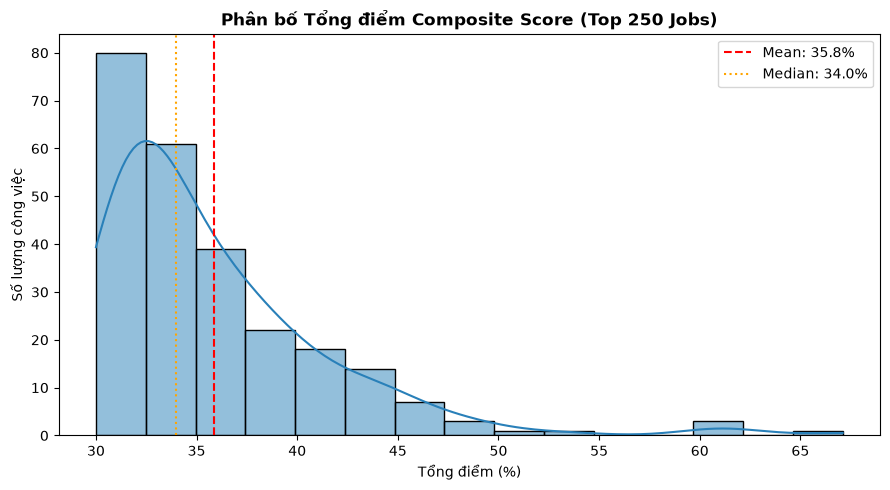

In [11]:
# Lấy phân bố điểm gợi ý của 250 việc làm hàng đầu từ Case 1
diagnostic_df = recommend_jobs(
    target_title="Python Developer Machine Learning",
    skills=["Python", "SQL", "Machine Learning"],
    user_exp=1.0,
    preferred_city="Hà Nội",
    preferred_work_modes=["Remote", "Hybrid"],
    top_n=250
)

plt.figure(figsize=(9, 5))
sns.histplot(diagnostic_df['Tổng điểm (%)'], bins=15, kde=True, color='#2980b9')
plt.axvline(diagnostic_df['Tổng điểm (%)'].mean(), color='red', linestyle='--', label=f"Mean: {diagnostic_df['Tổng điểm (%)'].mean():.1f}%")
plt.axvline(diagnostic_df['Tổng điểm (%)'].median(), color='orange', linestyle=':', label=f"Median: {diagnostic_df['Tổng điểm (%)'].median():.1f}%")
plt.title("Phân bố Tổng điểm Composite Score (Top 250 Jobs)", fontsize=12, fontweight='bold')
plt.xlabel("Tổng điểm (%)")
plt.ylabel("Số lượng công việc")
plt.legend()
plt.tight_layout()
plt.show()

print("=== THỐNG KÊ MÔ TẢ ĐIỂM SỐ GỢI Ý ===")
display(diagnostic_df['Tổng điểm (%)'].describe().round(2))


### 7.2. Điểm trung bình các thành phần trong Top 10 Gợi ý


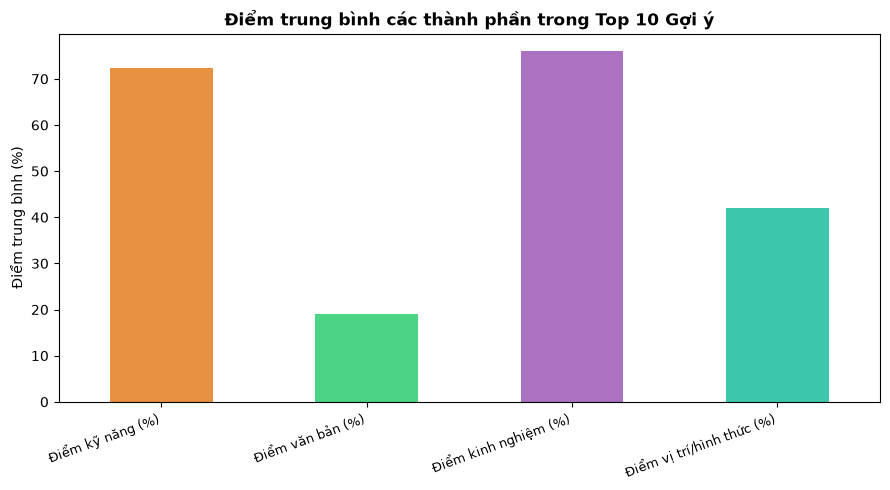

In [12]:
plt.figure(figsize=(9, 5))
top10_comp = diagnostic_df.head(10)[['Điểm kỹ năng (%)', 'Điểm văn bản (%)', 'Điểm kinh nghiệm (%)', 'Điểm vị trí/hình thức (%)']].mean()
top10_comp.plot(kind='bar', color=['#e67e22', '#2ecc71', '#9b59b6', '#1abc9c'], alpha=0.85)
plt.title("Điểm trung bình các thành phần trong Top 10 Gợi ý", fontsize=12, fontweight='bold')
plt.ylabel("Điểm trung bình (%)")
plt.xticks(rotation=20, ha='right', fontsize=9)
plt.tight_layout()
plt.show()


## 8. Đánh Giá & Đo Lường Hiệu Năng Hệ Thống Gợi Ý (Evaluation)

Chưa có log tương tác thật (click/apply) nên ta đánh giá bằng **25 hồ sơ ứng viên mẫu** thuộc 5 nhóm nghề IT. Một job được coi là *liên quan* nếu **tiêu đề** (đã bỏ dấu) khớp từ khóa của nhóm nghề đó, dùng regex có ranh giới từ để tránh khớp nhầm (vd. `ai` trong `maintain`).

**Các chỉ số:**
1. **Precision@5** - tỷ lệ job trong top 5 đúng nhóm nghề.
2. **NDCG@5** - chất lượng thứ hạng. Phần "lý tưởng" (IDCG) tính từ **toàn bộ kho** (lấy tối đa 5 job liên quan), nên một danh sách trượt hết sẽ bị điểm thấp. Bản cũ lấy IDCG từ chính top-5 nên *không phải NDCG thật*.
3. **ILD@5** - độ đa dạng trong danh sách (khoảng cách cosine trung bình giữa các job).
4. **SCR@5** - mức người dùng đáp ứng kỹ năng yêu cầu của các job gợi ý.
5. **Catalog Coverage** - phần trăm kho tin được gợi ý ít nhất một lần.

> **Hạn chế cần nhớ:** nhãn "liên quan" suy ra từ tiêu đề nên chỉ là *proxy*, và 25 hồ sơ là mẫu nhỏ (chênh lệch ~0,03 có thể chỉ là nhiễu). Để kết luận chắc chắn cần tập nhãn tay hoặc dữ liệu click thật.

In [ ]:
import unicodedata

def strip_accents(text):
    s = unicodedata.normalize('NFD', str(text).lower().replace('đ', 'd'))
    return ''.join(c for c in s if unicodedata.category(c) != 'Mn')

# 1. 25 hồ sơ ứng viên mẫu (kỹ năng viết theo tên chuẩn của từ điển)
test_benchmark_profiles = [
    {"domain": "Backend", "title": "Backend Python Developer", "skills": ["Python", "Django", "FastAPI", "PostgreSQL", "Docker", "Redis"], "exp": 2.0, "city": "Hà Nội"},
    {"domain": "Backend", "title": "Java Spring Boot Engineer", "skills": ["Java", "Spring Boot", "MySQL", "Microservices", "Apache Kafka"], "exp": 3.0, "city": "Hồ Chí Minh"},
    {"domain": "Backend", "title": "Node.js Backend Developer", "skills": ["Node.js", "Express.js", "MongoDB", "TypeScript", "Redis"], "exp": 2.0, "city": "Tất cả"},
    {"domain": "Backend", "title": ".NET Software Engineer", "skills": [".NET", "C#", "SQL Server"], "exp": 3.0, "city": "Đà Nẵng"},
    {"domain": "Backend", "title": "Golang Backend Engineer", "skills": ["Golang", "gRPC", "Docker", "Kubernetes", "PostgreSQL"], "exp": 2.5, "city": "Hồ Chí Minh"},
    {"domain": "Frontend/Mobile", "title": "Frontend React Developer", "skills": ["React", "JavaScript", "TypeScript", "HTML/CSS", "Redux"], "exp": 2.0, "city": "Hà Nội"},
    {"domain": "Frontend/Mobile", "title": "Vue.js Frontend Engineer", "skills": ["Vue", "Nuxt.js", "JavaScript", "TailwindCSS"], "exp": 1.5, "city": "Hồ Chí Minh"},
    {"domain": "Frontend/Mobile", "title": "Mobile Flutter Developer", "skills": ["Flutter", "Dart", "Firebase", "REST API"], "exp": 2.0, "city": "Tất cả"},
    {"domain": "Frontend/Mobile", "title": "iOS Swift Developer", "skills": ["iOS", "Swift"], "exp": 3.0, "city": "Hà Nội"},
    {"domain": "Frontend/Mobile", "title": "Android Kotlin Developer", "skills": ["Android", "Kotlin", "Java"], "exp": 2.0, "city": "Hồ Chí Minh"},
    {"domain": "Data/AI", "title": "Data Analyst", "skills": ["SQL", "Python", "Power BI", "Tableau", "Excel"], "exp": 1.5, "city": "Hà Nội"},
    {"domain": "Data/AI", "title": "Data Engineer", "skills": ["Python", "SQL", "Apache Spark", "Apache Kafka", "Hadoop", "Apache Airflow"], "exp": 3.0, "city": "Hồ Chí Minh"},
    {"domain": "Data/AI", "title": "Machine Learning Engineer", "skills": ["Python", "PyTorch", "TensorFlow", "Scikit-Learn", "Docker"], "exp": 2.0, "city": "Tất cả"},
    {"domain": "Data/AI", "title": "AI NLP Engineer", "skills": ["Python", "NLP", "LLM"], "exp": 2.0, "city": "Hà Nội"},
    {"domain": "Data/AI", "title": "BI Developer", "skills": ["Power BI", "DAX", "SQL Server", "ETL", "Data Warehouse"], "exp": 2.5, "city": "Hồ Chí Minh"},
    {"domain": "DevOps/Cloud", "title": "DevOps Engineer", "skills": ["Docker", "Kubernetes", "CI/CD", "AWS", "Terraform", "Linux"], "exp": 3.0, "city": "Hà Nội"},
    {"domain": "DevOps/Cloud", "title": "Cloud Solutions Architect", "skills": ["AWS", "Azure", "GCP", "Microservices", "Docker"], "exp": 4.0, "city": "Hồ Chí Minh"},
    {"domain": "DevOps/Cloud", "title": "Site Reliability Engineer (SRE)", "skills": ["Linux", "Python", "Prometheus", "Grafana", "Kubernetes"], "exp": 3.0, "city": "Tất cả"},
    {"domain": "DevOps/Cloud", "title": "Cyber Security Specialist", "skills": ["An Ninh Mạng", "Linux"], "exp": 2.5, "city": "Hà Nội"},
    {"domain": "DevOps/Cloud", "title": "System Administrator", "skills": ["Linux", "VMware", "Bash"], "exp": 2.0, "city": "Hồ Chí Minh"},
    {"domain": "QA/QC", "title": "QA Automation Engineer", "skills": ["Selenium", "Python", "Java", "Postman", "CI/CD", "Git"], "exp": 2.0, "city": "Hà Nội"},
    {"domain": "QA/QC", "title": "Manual QC Tester", "skills": ["Jira", "SQL", "API Testing", "Software Testing"], "exp": 1.5, "city": "Hồ Chí Minh"},
    {"domain": "QA/QC", "title": "Software Test Engineer", "skills": ["Postman", "JMeter", "SQL"], "exp": 2.0, "city": "Tất cả"},
    {"domain": "QA/QC", "title": "Lead QA Engineer", "skills": ["Automation Testing", "Appium", "Selenium"], "exp": 4.0, "city": "Hà Nội"},
    {"domain": "QA/QC", "title": "QC Specialist Web/App", "skills": ["Software Testing", "Jira", "Postman"], "exp": 2.0, "city": "Hồ Chí Minh"},
]
DOMAINS = ["Backend", "Frontend/Mobile", "Data/AI", "DevOps/Cloud", "QA/QC"]

# 2. Định nghĩa "liên quan": tiêu đề (đã bỏ dấu) khớp từ khóa của nhóm nghề, có ranh giới từ
DOMAIN_PATTERNS = {
    "Backend": r"back.?end|\bjava\b|python|\bphp\b|\.net|dotnet|\bnode|golang|\bgo\b|ruby|\bc#|c\+\+|lap trinh vien|software (engineer|developer)|ky su phan mem",
    "Frontend/Mobile": r"front.?end|react|angular|\bvue|mobile|\bios\b|android|flutter|swift|kotlin|web developer|lap trinh web",
    "Data/AI": r"\bdata\b|\bai\b|machine learning|\bml\b|\bbi\b|analytics|du lieu|scientist|\bnlp\b|\bllm\b|computer vision",
    "DevOps/Cloud": r"devops|cloud|\bsre\b|\bsystem|he thong|ha tang|infrastructure|linux|security|an toan thong tin|an ninh|network|\bmang\b|quan tri",
    "QA/QC": r"\bqa\b|\bqc\b|test|kiem thu|chat luong|quality",
}
DOMAIN_REGEX = {d: re.compile(p) for d, p in DOMAIN_PATTERNS.items()}

def relevance_mask(df, domain):
    """Mảng bool: job nào trong df thuộc nhóm nghề `domain` (dựa trên tiêu đề)."""
    return df['title'].map(strip_accents).map(lambda t: bool(DOMAIN_REGEX[domain].search(t))).values

REL_MASK = {d: relevance_mask(jobs, d) for d in DOMAINS}
print("Số job liên quan trong kho (dùng làm IDCG):", {d: int(m.sum()) for d, m in REL_MASK.items()})

def ndcg_at_k(rel_list, total_relevant, k=5):
    """NDCG thật: IDCG tính từ toàn bộ kho (tối đa k job liên quan), không phải từ chính danh sách gợi ý."""
    rel = np.asarray(rel_list, dtype=float)[:k]
    dcg = np.sum(rel / np.log2(np.arange(2, len(rel) + 2)))
    ideal_n = min(int(total_relevant), k)
    idcg = np.sum(1.0 / np.log2(np.arange(2, ideal_n + 2)))
    return float(dcg / idcg) if idcg > 0 else 0.0

# 3. Chạy toàn bộ pipeline gợi ý trên 25 hồ sơ
K = 5
rows, all_recommended = [], set()
for prof in test_benchmark_profiles:
    rec = recommend_jobs(target_title=prof['title'], skills=prof['skills'], user_exp=prof['exp'],
                         preferred_city=prof['city'], top_n=K)
    ids = rec['job_id'].tolist()
    all_recommended.update(ids)
    idx = [jobs.index[jobs['job_id'] == j][0] for j in ids]
    rel = [bool(REL_MASK[prof['domain']][i]) for i in idx]

    user_set = {s.lower() for s in prof['skills']}
    scr = np.mean([
        (len(user_set & {x.strip().lower() for x in str(jobs.at[i, 'required_skills']).split(',') if x.strip()}) /
         max(1, len([x for x in str(jobs.at[i, 'required_skills']).split(',') if x.strip()])))
        for i in idx])
    sim = cosine_similarity(tfidf_matrix[idx])
    ild = float(np.mean([1 - sim[a, b] for a in range(len(idx)) for b in range(a + 1, len(idx))]))
    rows.append({'Nhóm nghề': prof['domain'], 'Hồ sơ': prof['title'], 'P@5': np.mean(rel),
                 'NDCG@5': ndcg_at_k(rel, REL_MASK[prof['domain']].sum(), K), 'ILD@5': ild, 'SCR@5': scr})

res = pd.DataFrame(rows)
print("=" * 80)
print("   KẾT QUẢ ĐÁNH GIÁ TOÀN PIPELINE (25 hồ sơ, top-5)")
print("=" * 80)
print(res[['P@5', 'NDCG@5', 'ILD@5', 'SCR@5']].mean().round(3).to_string())
print(f"Catalog coverage: {len(all_recommended) / len(jobs):.1%} ({len(all_recommended)}/{len(jobs)} jobs)")
print("\n--- Theo từng nhóm nghề ---")
display(res.groupby('Nhóm nghề')[['P@5', 'NDCG@5', 'ILD@5', 'SCR@5']].mean().round(3).loc[DOMAINS])
print("--- Chi tiết từng hồ sơ ---")
display(res.round(3))

### 8.1. Bảng Ablation: từng cải tiến đóng góp bao nhiêu?

Để biết mỗi thay đổi có thật sự giúp ích không, ta chạy cùng 25 hồ sơ nhưng **chỉ dùng độ tương đồng văn bản** (TF-IDF cosine trên *Title + Skills*) và đổi từng thành phần một:

| Biến thể | Soup | Tokenizer | Tập tin |
|---|---|---|---|
| **A** | Kỹ năng **lẫn** thẻ ngành ×4 (mô phỏng soup cũ) | cũ | Tất cả |
| **B** | như A | **mới** | Tất cả |
| **C** | Chỉ kỹ năng công nghệ ×4 | mới | Tất cả |
| **D** | như C | mới | **Chỉ IT** |
| **E** | D + thẻ ngành ×1 (**cấu hình đang dùng**) | mới | Chỉ IT |
| **F** | như D | **cũ** | Chỉ IT |

In [ ]:
def tfidf_old():
    return TfidfVectorizer(token_pattern=r"(?u)\b[a-zA-Z0-9_+#\.]+\b", max_features=10000, ngram_range=(1, 2), min_df=2)

def tfidf_new():
    return TfidfVectorizer(preprocessor=normalize_tech_text, token_pattern=TOKEN_PATTERN, max_features=10000, ngram_range=(1, 2), min_df=2)

soup_mixed = lambda r: f"{r.title} " * 3 + f"{r.required_skills}, {r.job_tags} " * 4 + r.description_clean
soup_skills = lambda r: f"{r.title} " * 3 + f"{r.required_skills} " * 4 + r.description_clean
soup_final = lambda r: f"{r.title} " * 3 + f"{r.required_skills} " * 4 + f"{r.job_tags} " + r.description_clean

def text_only_eval(df, soup_fn, vec, k=10):
    """Xếp hạng chỉ bằng cosine TF-IDF giữa (Title + Skills) của hồ sơ và Content Soup của job."""
    X = vec.fit_transform(df.apply(soup_fn, axis=1))
    masks = {d: relevance_mask(df, d) for d in DOMAINS}
    p5, p10, nd = [], [], []
    for prof in test_benchmark_profiles:
        q = f"{prof['title']} " * 3 + (" ".join(prof['skills']) + " ") * 4
        s = cosine_similarity(vec.transform([q]), X).ravel()
        top = np.argsort(-s)[:k]
        rel = masks[prof['domain']][top].astype(float)
        p5.append(rel[:5].mean()); p10.append(rel.mean())
        nd.append(ndcg_at_k(rel, masks[prof['domain']].sum(), k))
    return len(df), np.mean(p5), np.mean(p10), np.mean(nd)

variants = [
    ("A. Soup cũ (kỹ năng lẫn thẻ) + tokenizer cũ + tất cả tin", jobs_all, soup_mixed,  tfidf_old()),
    ("B. A + tokenizer mới",                                      jobs_all, soup_mixed,  tfidf_new()),
    ("C. B + chỉ kỹ năng công nghệ (bỏ thẻ)",                     jobs_all, soup_skills, tfidf_new()),
    ("D. C + lọc tin IT",                                         jobs,     soup_skills, tfidf_new()),
    ("E. D + thẻ ngành x1  [ĐANG DÙNG]",                          jobs,     soup_final,  tfidf_new()),
    ("F. D nhưng tokenizer cũ",                                   jobs,     soup_skills, tfidf_old()),
]
ablation = pd.DataFrame(
    [(name, *text_only_eval(df, fn, vec)) for name, df, fn, vec in variants],
    columns=['Biến thể', 'Số tin', 'P@5', 'P@10', 'NDCG@10']).round(3)
display(ablation)

print("""CÁCH ĐỌC KẾT QUẢ
- Tokenizer mới giúp nhất quán: B > A và D > F.
- Việc tách kỹ năng khỏi thẻ ngành (C) và lọc tin IT (D, E) KHÔNG cho chênh lệch đáng tin ở mức 25 hồ sơ: các thay đổi này
  được giữ vì lý do thiết kế (điểm khớp kỹ năng chiếm 30% trọng số nên cần kỹ năng sạch; tin thiết kế/kinh doanh không nên lọt vào gợi ý),
  chứ không phải vì con số ở bảng này.
- 'Liên quan' chỉ là proxy từ tiêu đề; muốn kết luận chắc cần tập nhãn tay hoặc dữ liệu click.""")

### 8.2. Bảng Ablation công thức chấm điểm: từng bản sửa đóng góp bao nhiêu?

Chạy **toàn pipeline** `recommend_jobs` (không chỉ văn bản) trên 25 hồ sơ, bật dần từng bản sửa ở mục 5:

| Biến thể | Điểm kỹ năng | Điểm văn bản |
|---|---|---|
| **V0** (công thức cũ) | coverage thô, job không kỹ năng = 0,5 | cosine thô |
| **V1** | như V0 | **chuẩn hóa theo truy vấn** |
| **V2** | **có hệ số tin cậy** m/(m+1), job không kỹ năng bị loại | chuẩn hóa theo truy vấn (**cấu hình đang dùng**) |

Cột *"Chỉ văn bản"* là mức trần tham chiếu (xếp hạng chỉ bằng cosine TF-IDF, như ở mục 8.1).

In [ ]:
def full_pipeline_eval(label, **kwargs):
    p5, nd, cov = [], [], set()
    for prof in test_benchmark_profiles:
        rec = recommend_jobs(target_title=prof['title'], skills=prof['skills'], user_exp=prof['exp'],
                             preferred_city=prof['city'], top_n=5, **kwargs)
        idx = [jobs.index[jobs['job_id'] == j][0] for j in rec['job_id']]
        rel = [bool(REL_MASK[prof['domain']][i]) for i in idx]
        p5.append(np.mean(rel)); nd.append(ndcg_at_k(rel, REL_MASK[prof['domain']].sum(), 5)); cov.update(idx)
    return {'Biến thể': label, 'P@5': np.mean(p5), 'NDCG@5': np.mean(nd), 'Catalog coverage': len(cov) / len(jobs)}

scoring_ablation = pd.DataFrame([
    full_pipeline_eval("V0. Công thức cũ",                          skill_mode='v1', normalize_text=False),
    full_pipeline_eval("V1. + chuẩn hóa điểm văn bản",               skill_mode='v1', normalize_text=True),
    full_pipeline_eval("V2. + hệ số tin cậy kỹ năng [ĐANG DÙNG]",    skill_mode='v2', normalize_text=True),
])
ref = text_only_eval(jobs, soup_final, tfidf_new())
scoring_ablation.loc[len(scoring_ablation)] = {'Biến thể': "Tham chiếu: chỉ văn bản (mức trần)", 'P@5': ref[1], 'NDCG@5': ref[3], 'Catalog coverage': np.nan}
display(scoring_ablation.round(3))

### 8.3. Quét trọng số: tỷ lệ Kỹ năng : Văn bản nên là bao nhiêu?

Trọng số đặt tay ban đầu là $0{,}40 S_{skills} + 0{,}30 S_{text} + \dots$. Sau khi sửa điểm kỹ năng và điểm văn bản, ta kiểm tra lại.

**Chỉ quét tỷ lệ Kỹ năng : Văn bản** (tổng cố định 0,70), còn Kinh nghiệm / Vị trí / Lương giữ 0,10 mỗi thành phần. Lý do: nhãn "liên quan" của ta chỉ dựa trên *nhóm nghề của tiêu đề*, nó **không thể đánh giá** việc đúng thành phố, đủ kinh nghiệm hay đạt mức lương. Nếu quét cả ba thành phần này, phép đo sẽ kết luận sai là chúng nên bằng 0.

Để tránh chọn trọng số chỉ vì hợp với 25 hồ sơ mẫu, ta **chia đôi hồ sơ** (chẵn/lẻ) và xem kết quả có nhất quán ở cả hai nửa không.

> **Cách đọc kết quả (quan trọng):** truy vấn của hồ sơ chứa tiêu đề ×3 và nhãn "liên quan" cũng suy ra từ tiêu đề, nên điểm văn bản vốn dĩ khớp với nhãn. Vì vậy phép đo luôn có xu hướng ủng hộ trọng số văn bản, và việc `w_skills = 0` đứng đầu **không có nghĩa** là nên bỏ điểm kỹ năng (kỹ năng vẫn quyết định người dùng *đủ điều kiện* hay không, thể hiện ở cột SCR). Kết luận đáng tin chỉ gồm hai điều: (1) từ `w_skills ≥ 0,5` chất lượng giảm mạnh ở cả hai nửa; (2) `0,2-0,3` luôn tốt hơn `0,4`. Do đó chọn mức vừa phải **0,30 : 0,40**.

In [ ]:
# 1. Tính MỘT LẦN các thành phần điểm cho 25 hồ sơ (không phụ thuộc trọng số)
comp_cache, cov_cache = [], []
for prof in test_benchmark_profiles:
    sc = score_components(prof['title'], "", prof['skills'], prof['exp'], prof['city'])
    comp_cache.append((prof['domain'], sc))
    user_set = {s.lower() for s in sc['user_skills']}
    # tỷ lệ kỹ năng job yêu cầu mà hồ sơ có (NaN nếu job không liệt kê kỹ năng)
    cov_cache.append(np.array([len(user_set & {x.lower() for x in req}) / len(req) if req else np.nan for req in jobs['req_list']]))

def eval_weights(weights, profile_ids):
    p5, nd, scr = [], [], []
    for k in profile_ids:
        dom, sc = comp_cache[k]
        total = np.where(sc['active'], combine_scores(sc['comps'], weights), -1.0)
        top = np.argsort(-total, kind='stable')[:5]
        rel = REL_MASK[dom][top]
        p5.append(rel.mean()); nd.append(ndcg_at_k(rel, REL_MASK[dom].sum(), 5))
        scr.append(np.nanmean(cov_cache[k][top]) if not np.all(np.isnan(cov_cache[k][top])) else np.nan)
    return np.mean(p5), np.mean(nd), np.nanmean(scr)

# 2. Quét w_skills từ 0.0 đến 0.7 (w_text = 0.7 - w_skills)
all_ids, fold_a, fold_b = list(range(25)), list(range(0, 25, 2)), list(range(1, 25, 2))
sweep = []
for w_sk in np.round(np.arange(0.0, 0.71, 0.1), 1):
    w = {'skills': w_sk, 'text': round(0.7 - w_sk, 1), 'exp': 0.10, 'loc': 0.10, 'sal': 0.10}
    p5, nd, scr = eval_weights(w, all_ids)
    sweep.append({'w_skills': w_sk, 'w_text': w['text'], 'P@5': p5, 'NDCG@5': nd, 'SCR@5': scr,
                  'NDCG@5 (nửa A)': eval_weights(w, fold_a)[1], 'NDCG@5 (nửa B)': eval_weights(w, fold_b)[1]})
sweep = pd.DataFrame(sweep).set_index('w_skills')
display(sweep.round(3))

cur = DEFAULT_WEIGHTS['skills']
print(f"Đang dùng (w_skills = {cur}): NDCG@5 nửa A = {sweep.loc[cur, 'NDCG@5 (nửa A)']:.3f}, nửa B = {sweep.loc[cur, 'NDCG@5 (nửa B)']:.3f}")
print(f"Mức cũ    (w_skills = 0.4): NDCG@5 nửa A = {sweep.loc[0.4, 'NDCG@5 (nửa A)']:.3f}, nửa B = {sweep.loc[0.4, 'NDCG@5 (nửa B)']:.3f}")